# SMS Spam Detection

## Importing Libraries

In [111]:
import pandas as pd
import numpy as np
import string
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from wordcloud import WordCloud
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score
import pickle

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\jkh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jkh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jkh\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Loading the Dataset

In [112]:
df=pd.read_csv("spam.csv", encoding="latin-1")

In [113]:
df.sample(6)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
5222,ham,5 nights...We nt staying at port step liao...T...,NaN,NaN,NaN
745,ham,Dunno he jus say go lido. Same time 930.,NaN,NaN,NaN
1993,ham,Eh den sat u book e kb liao huh...,NaN,NaN,NaN
2181,ham,Ok.,NaN,NaN,NaN
431,ham,Does she usually take fifteen fucking minutes ...,NaN,NaN,NaN
4113,ham,Where are you ? What do you do ? How can you s...,NaN,NaN,NaN


In [114]:
df.shape

(5572, 5)

## Cleaning and Exploratory Data Analysis (EDA) 

In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


In [116]:
df=df.drop(columns=["Unnamed: 2","Unnamed: 3","Unnamed: 4"])

In [117]:
df=df.rename(columns={"v1":"Target","v2":"Text"})

In [118]:
df.head(6)

,Target,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...


In [119]:
encoder=LabelEncoder()
df['Target']=encoder.fit_transform(df['Target'])

In [120]:
df.isnull().sum()

Target    0
Text      0
dtype: int64

In [121]:
df.duplicated().sum()

np.int64(403)

In [122]:
df=df.drop_duplicates(keep='first')

In [123]:
df.shape

(5169, 2)

In [124]:
df['Target'].value_counts()

Target
0    4516
1     653
Name: count, dtype: int64

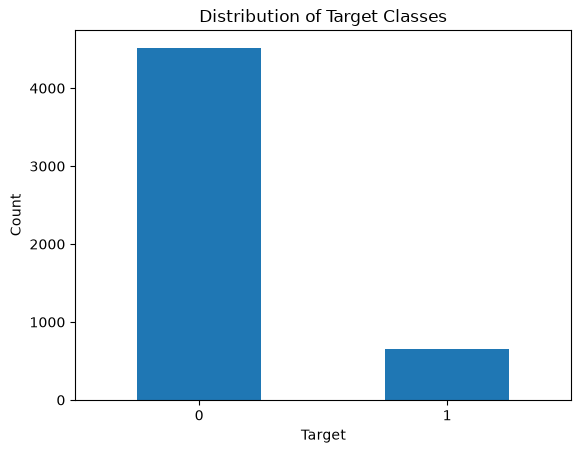

In [125]:
df["Target"].value_counts().plot(kind="bar")

plt.title("Distribution of Target Classes")
plt.xlabel("Target")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

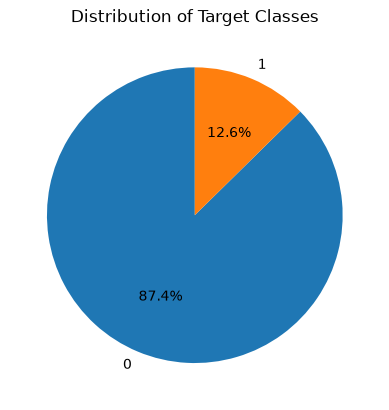

In [126]:

df["Target"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Target Classes")
plt.ylabel("")
plt.show()

In [127]:
df['num_char']=df['Text'].apply(len)
df['num_words']=df['Text'].apply(lambda x: len(nltk.word_tokenize(x)))
df['num_senten']=df['Text'].apply(lambda x: len(nltk.sent_tokenize(x)))


In [128]:
df.head()

,Target,Text,num_char,num_words,num_senten
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [129]:
df.describe()

,Target,num_char,num_words,num_senten
count,5169.000000,5169.000000,5169.000000,5169.000000
mean,0.126330,78.977945,18.460437,1.965564
std,0.332253,58.236293,13.334441,1.448541
min,0.000000,2.000000,1.000000,1.000000
25%,0.000000,36.000000,9.000000,1.000000
50%,0.000000,60.000000,15.000000,1.000000
75%,0.000000,117.000000,26.000000,2.000000
max,1.000000,910.000000,220.000000,38.000000


<Axes: xlabel='num_char', ylabel='Count'>

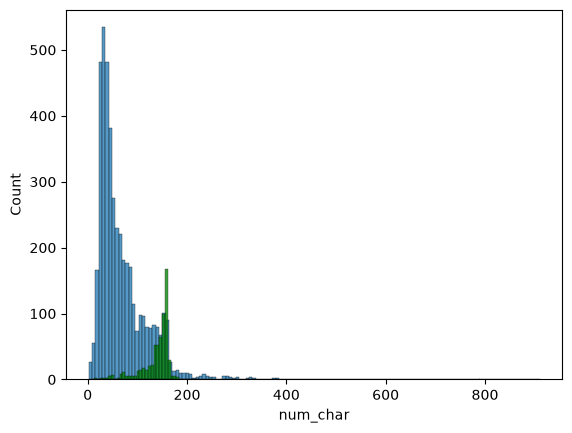

In [130]:
sns.histplot(df[df["Target"]== 0]["num_char"]) #Spam
sns.histplot(df[df["Target"]== 1]["num_char"],color='green')

In [131]:
df.corr(numeric_only=True)

,Target,num_char,num_words,num_senten
Target,1.000000,0.384717,0.262720,0.263939
num_char,0.384717,1.000000,0.965686,0.624139
num_words,0.262720,0.965686,1.000000,0.679767
num_senten,0.263939,0.624139,0.679767,1.000000


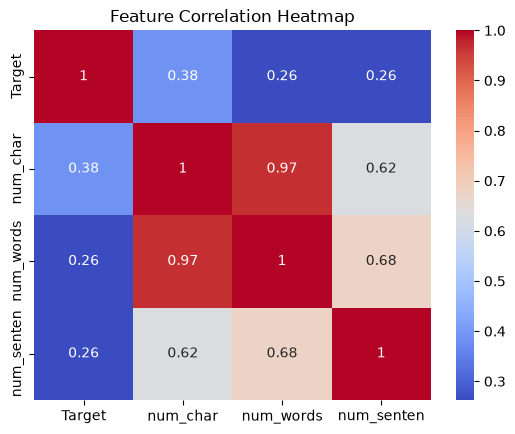

In [132]:
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Feature Correlation Heatmap")
plt.show()

## Text Preprocessing
- Converting Text to Lowercase
- Removing Stop Words
- Tokenisation
- Stemming

In [133]:
ps = PorterStemmer()
stop_words = set(stopwords.words('english'))

In [134]:
def trans_text(t):
    t = t.lower()                         
    t = nltk.word_tokenize(t)              

    y = []
    for i in t:
        if i.isalnum() and i not in stop_words:
            y.append(i)                   # Remove punctuation and stop words
    
    # return y

    y = [ps.stem(i) for i in y]            # Apply stemming

    return " ".join(y)                     



In [135]:
trans_text(df['Text'][0])

'go jurong point crazi avail bugi n great world la e buffet cine got amor wat'

In [136]:
df["trans_text"]=df["Text"].apply(trans_text)

In [137]:
df.head()

,Target,Text,num_char,num_words,num_senten,trans_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


### Word Cloud Visualisation

In [138]:
wc=WordCloud(width=500,height=500,min_font_size=10,background_color='white')

In [139]:
x=wc.generate(df[df['Target']==1]['trans_text'].str.cat(sep=' '))

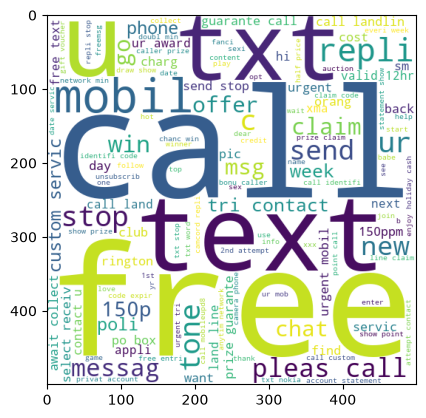

In [140]:
plt.imshow(x)

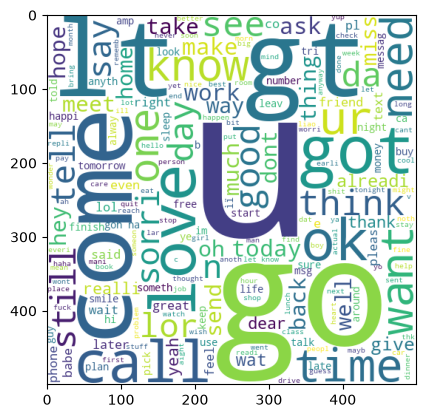

In [141]:
y=wc.generate(df[df['Target']==0]['trans_text'].str.cat(sep=' '))
plt.imshow(y)

## Model Building

In [142]:
gnb=GaussianNB()
mnb=MultinomialNB()
bnb=BernoulliNB()
cv=CountVectorizer()
tf=TfidfVectorizer()

## Model Building using Text Vectorisation

In [143]:
x=cv.fit_transform(df['trans_text']).toarray()

In [144]:
x.shape

(5169, 6715)

In [145]:
y=df['Target'].values

In [146]:
y

array([0, 0, 1, ..., 0, 0, 0], shape=(5169,))

In [147]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [148]:
gnb.fit(x_train,y_train)
gnby_predict=gnb.predict(x_test)
print(accuracy_score(y_test,gnby_predict))
print(confusion_matrix(y_test,gnby_predict))
print(precision_score(y_test,gnby_predict))

0.8800773694390716
[[792 104]
 [ 20 118]]
0.5315315315315315


In [149]:
mnb.fit(x_train,y_train)
mnby_predict=mnb.predict(x_test)
print(accuracy_score(y_test,mnby_predict))
print(confusion_matrix(y_test,mnby_predict))
print(precision_score(y_test,mnby_predict))

0.9642166344294004
[[871  25]
 [ 12 126]]
0.8344370860927153


In [150]:
bnb.fit(x_train,y_train)
bnby_predict=bnb.predict(x_test)
print(accuracy_score(y_test,bnby_predict))
print(confusion_matrix(y_test,bnby_predict))
print(precision_score(y_test,bnby_predict))

0.9700193423597679
[[893   3]
 [ 28 110]]
0.9734513274336283


## Model Building using TFIDF verification

In [151]:
tf = TfidfVectorizer(max_features=3000)

In [152]:
x1=tf.fit_transform(df['trans_text']).toarray()

In [153]:
x1_train,x1_test,y1_train,y1_test=train_test_split(x1,y,test_size=0.2,random_state=2)

In [154]:
mnb.fit(x1_train,y1_train)
mnby_predict1=mnb.predict(x1_test)
print(accuracy_score(y1_test,mnby_predict1))
print(confusion_matrix(y1_test,mnby_predict1))
print(precision_score(y1_test,mnby_predict1))

0.9709864603481625
[[896   0]
 [ 30 108]]
1.0


In [155]:
bnb.fit(x1_train,y1_train)
bnby_predict1=bnb.predict(x1_test)
print(accuracy_score(y1_test,bnby_predict1))
print(confusion_matrix(y1_test,bnby_predict1))
print(precision_score(y1_test,bnby_predict1))

0.9835589941972921
[[895   1]
 [ 16 122]]
0.991869918699187


## Saving the Best Model (MultinomialNB)

In [157]:
pickle.dump(tf,open('vectorizer.pkl','wb'))
pickle.dump(mnb,open('model.pkl','wb'))